In [1]:

# بازی دوز: تعریف وضعیت صفحه و حرکت‌های مجاز

EMPTY = " "
HUMAN = "X"
AGENT = "O"

def create_board():
    """ساخت صفحه خالی ۳ در ۳"""
    return [[EMPTY for _ in range(3)] for _ in range(3)]


def print_board(board):
    """نمایش صفحه بازی"""
    for row in board:
        print(" | ".join(cell if cell != EMPTY else "-" for cell in row))
        print("-" * 9)


def available_moves(board):
    """برگرداندن خانه‌های خالی"""
    moves = []
    for row in range(3):
        for col in range(3):
            if board[row][col] == EMPTY:
                moves.append((row, col))
    return moves


def make_move(board, move, player):
    """انجام حرکت در خانه خالی"""
    row, col = move
    if board[row][col] == EMPTY:
        board[row][col] = player
        return True
    return False


# آزمایش اولیه
board = create_board()
print("صفحه شروع بازی:")
print_board(board)

print("تعداد حرکت‌های مجاز:", len(available_moves(board)))


صفحه شروع بازی:
- | - | -
---------
- | - | -
---------
- | - | -
---------
تعداد حرکت‌های مجاز: 9


In [2]:
# بررسی برنده بازی

def check_winner(board):
    """بررسی ردیف‌ها، ستون‌ها و قطرها"""

    # بررسی ردیف‌ها
    for row in board:
        if row[0] == row[1] == row[2] != EMPTY:
            return row[0]

    # بررسی ستون‌ها
    for col in range(3):
        if board[0][col] == board[1][col] == board[2][col] != EMPTY:
            return board[0][col]

    # بررسی قطرها
    if board[0][0] == board[1][1] == board[2][2] != EMPTY:
        return board[0][0]

    if board[0][2] == board[1][1] == board[2][0] != EMPTY:
        return board[0][2]

    return None


def is_draw(board):
    """اگر صفحه پر باشد و برنده‌ای نداشته باشیم، بازی مساوی است"""
    return check_winner(board) is None and len(available_moves(board)) == 0


# آزمایش تابع‌ها
test_board = create_board()
test_board[0] = ["X", "X", "X"]

print_board(test_board)
print("برنده:", check_winner(test_board))
print("آیا بازی مساوی است؟", is_draw(test_board))

X | X | X
---------
- | - | -
---------
- | - | -
---------
برنده: X
آیا بازی مساوی است؟ False


In [3]:
# الگوریتم Minimax با امکان محدود کردن عمق جست‌وجو

def minimax(board, depth, maximizing, max_depth, stats):
    stats["states"] += 1

    winner = check_winner(board)

    if winner == AGENT:
        return 10 - depth, None

    if winner == HUMAN:
        return depth - 10, None

    moves = available_moves(board)

    if not moves:
        return 0, None

    if depth >= max_depth:
        return 0, None

    best_move = None

    if maximizing:
        best_score = float("-inf")

        for move in moves:
            make_move(board, move, AGENT)

            score, _ = minimax(
                board, depth + 1, False, max_depth, stats
            )

            board[move[0]][move[1]] = EMPTY

            if score > best_score:
                best_score = score
                best_move = move

        return best_score, best_move

    else:
        best_score = float("inf")

        for move in moves:
            make_move(board, move, HUMAN)

            score, _ = minimax(
                board, depth + 1, True, max_depth, stats
            )

            board[move[0]][move[1]] = EMPTY

            if score < best_score:
                best_score = score
                best_move = move

        return best_score, best_move


# آزمایش الگوریتم با عمق جست‌وجوی 3
board = create_board()
stats = {"states": 0}

score, move = minimax(board, 0, True, 3, stats)

print("امتیاز حرکت:", score)
print("بهترین حرکت پیشنهادی (ردیف، ستون):", move)
print("تعداد وضعیت‌های بررسی‌شده:", stats["states"])

امتیاز حرکت: 0
بهترین حرکت پیشنهادی (ردیف، ستون): (0, 0)
تعداد وضعیت‌های بررسی‌شده: 586


In [4]:
import time
import pandas as pd

depths = [1, 2, 3, 4, 5, 6, 7, 8, 9]
results = []

for depth_limit in depths:
    board = create_board()
    stats = {"states": 0}

    start_time = time.perf_counter()

    score, move = minimax(
        board, 0, True, depth_limit, stats
    )

    elapsed_time = time.perf_counter() - start_time

    results.append({
        "عمق جست‌وجو": depth_limit,
        "امتیاز": score,
        "حرکت پیشنهادی": move,
        "تعداد وضعیت‌ها": stats["states"],
        "زمان اجرا (ثانیه)": elapsed_time
    })

results_df = pd.DataFrame(results)
results_df

,عمق جست‌وجو,امتیاز,حرکت پیشنهادی,تعداد وضعیت‌ها,زمان اجرا (ثانیه)
0,1,0,"(0, 0)",10,0.000040
1,2,0,"(0, 0)",82,0.000223
2,3,0,"(0, 0)",586,0.001426
3,4,0,"(0, 0)",3610,0.008590
4,5,0,"(0, 0)",18730,0.040876
5,6,0,"(0, 0)",73450,0.154601
6,7,0,"(0, 0)",221626,0.425808
7,8,0,"(0, 0)",422074,0.740029
8,9,0,"(0, 0)",549946,0.929542


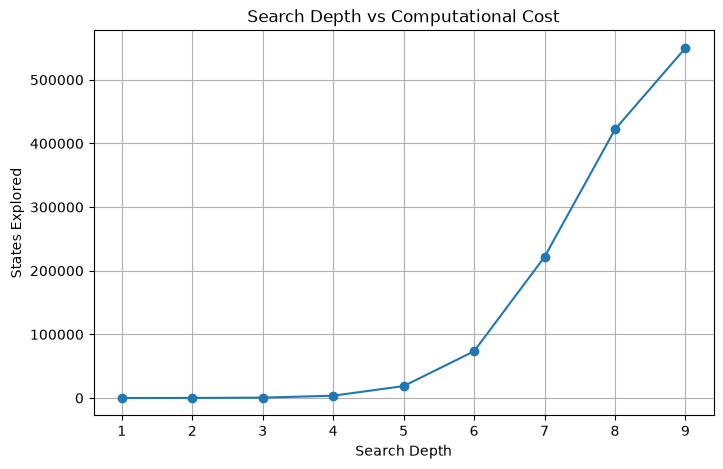

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    results_df["عمق جست‌وجو"],
    results_df["تعداد وضعیت‌ها"],
    marker="o"
)

plt.xlabel("Search Depth")
plt.ylabel("States Explored")
plt.title("Search Depth vs Computational Cost")
plt.grid(True)
plt.show()

In [6]:
# ارزیابی وضعیت صفحه در عمق محدود

def evaluate_board(board):
    lines = []

    # ردیف‌ها
    lines.extend(board)

    # ستون‌ها
    for col in range(3):
        lines.append([board[row][col] for row in range(3)])

    # قطرها
    lines.append([board[i][i] for i in range(3)])
    lines.append([board[i][2 - i] for i in range(3)])

    score = 0

    for line in lines:
        agent_count = line.count(AGENT)
        human_count = line.count(HUMAN)

        if human_count == 0:
            if agent_count == 2:
                score += 5
            elif agent_count == 1:
                score += 1

        if agent_count == 0:
            if human_count == 2:
                score -= 5
            elif human_count == 1:
                score -= 1

    return score

In [7]:
test_board = create_board()
test_board[0][0] = AGENT
test_board[0][1] = AGENT
test_board[1][0] = HUMAN

print_board(test_board)
print("امتیاز ارزیابی صفحه:", evaluate_board(test_board))

O | O | -
---------
X | - | -
---------
- | - | -
---------
امتیاز ارزیابی صفحه: 6


In [9]:
def minimax(board, depth, maximizing, max_depth, stats):
    stats["states"] += 1

    winner = check_winner(board)

    if winner == AGENT:
        return 10 - depth, None

    if winner == HUMAN:
        return depth - 10, None

    moves = available_moves(board)

    if not moves:
        return 0, None

    if depth >= max_depth:
        return evaluate_board(board), None

    best_move = None

    if maximizing:
        best_score = float("-inf")

        for move in moves:
            make_move(board, move, AGENT)

            score, _ = minimax(
                board, depth + 1, False, max_depth, stats
            )

            board[move[0]][move[1]] = EMPTY

            if score > best_score:
                best_score = score
                best_move = move

        return best_score, best_move

    else:
        best_score = float("inf")

        for move in moves:
            make_move(board, move, HUMAN)

            score, _ = minimax(
                board, depth + 1, True, max_depth, stats
            )

            board[move[0]][move[1]] = EMPTY

            if score < best_score:
                best_score = score
                best_move = move

        return best_score, best_move

In [10]:
board = create_board()
stats = {"states": 0}

score, move = minimax(board, 0, True, 3, stats)

print("امتیاز حرکت:", score)
print("حرکت پیشنهادی:", move)
print("تعداد وضعیت‌های بررسی‌شده:", stats["states"])


امتیاز حرکت: 7
حرکت پیشنهادی: (1, 1)
تعداد وضعیت‌های بررسی‌شده: 586


In [11]:
import time
import pandas as pd

depths = [1, 2, 3, 4, 5, 6, 7]
improved_results = []

for depth_limit in depths:
    board = create_board()
    stats = {"states": 0}

    start_time = time.perf_counter()

    score, move = minimax(
        board, 0, True, depth_limit, stats
    )

    elapsed_time = time.perf_counter() - start_time

    improved_results.append({
        "عمق جست‌وجو": depth_limit,
        "امتیاز": score,
        "حرکت پیشنهادی": move,
        "تعداد وضعیت‌ها": stats["states"],
        "زمان اجرا (ثانیه)": elapsed_time
    })

improved_df = pd.DataFrame(improved_results)
improved_df

,عمق جست‌وجو,امتیاز,حرکت پیشنهادی,تعداد وضعیت‌ها,زمان اجرا (ثانیه)
0,1,4,"(1, 1)",10,0.000081
1,2,1,"(1, 1)",82,0.000490
2,3,7,"(1, 1)",586,0.003225
3,4,0,"(1, 1)",3610,0.019178
4,5,6,"(1, 1)",18730,0.087210
5,6,0,"(1, 1)",73450,0.309380
6,7,5,"(0, 0)",221626,0.726442


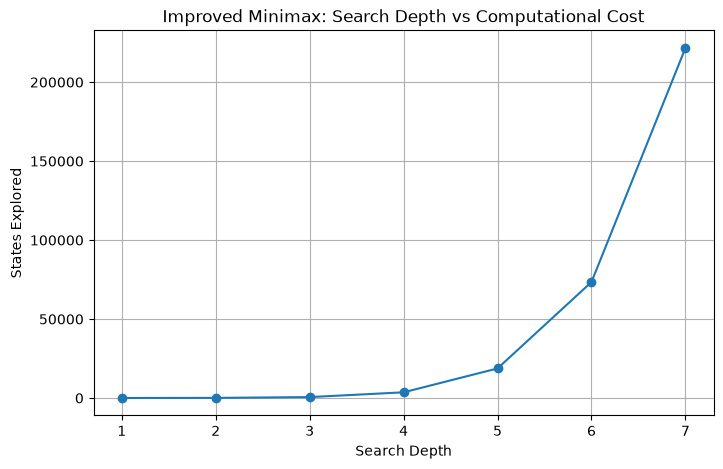

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    improved_df["عمق جست‌وجو"],
    improved_df["تعداد وضعیت‌ها"],
    marker="o"
)

plt.xlabel("Search Depth")
plt.ylabel("States Explored")
plt.title("Improved Minimax: Search Depth vs Computational Cost")
plt.grid(True)
plt.show()